# 01 EDA: C-MAPSS FD001

Goal: understand the data before modeling. Questions:
1. How long do engines live, and how are the test engines truncated?
2. Which sensors are constant or uninformative?
3. How do the informative sensors trend as an engine approaches failure?
4. How strongly does each sensor correlate with RUL?

Data: `uv run rul-data download` puts the raw files in `data/raw/`.

Note: this notebook is exploratory. RUL here is uncapped and the correlations are computed on all training rows. The modeling code (Milestone 2 onward) makes its own decisions on capping and splits.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rul.data import load_split, load_test_rul

FIG = Path("..") / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 80

# Sensor names from Saxena et al. (2008), Table 2
SENSOR_NAMES = {
    "s1": "T2 fan inlet temp",
    "s2": "T24 LPC outlet temp",
    "s3": "T30 HPC outlet temp",
    "s4": "T50 LPT outlet temp",
    "s5": "P2 fan inlet pressure",
    "s6": "P15 bypass duct pressure",
    "s7": "P30 HPC outlet pressure",
    "s8": "Nf physical fan speed",
    "s9": "Nc physical core speed",
    "s10": "epr engine pressure ratio",
    "s11": "Ps30 HPC outlet static pressure",
    "s12": "phi fuel flow / Ps30",
    "s13": "NRf corrected fan speed",
    "s14": "NRc corrected core speed",
    "s15": "BPR bypass ratio",
    "s16": "farB burner fuel-air ratio",
    "s17": "htBleed bleed enthalpy",
    "s18": "Nf_dmd demanded fan speed",
    "s19": "PCNfR_dmd demanded corrected fan speed",
    "s20": "W31 HPT coolant bleed",
    "s21": "W32 LPT coolant bleed",
}
train = load_split("FD001", "train")
test = load_split("FD001", "test")
true_rul = load_test_rul("FD001").to_frame()
print("train", train.shape, "engines", train.unit.nunique())
print("test ", test.shape, "engines", test.unit.nunique())
print("true RUL values", len(true_rul))
train.head()

train (20631, 26) engines 100
test  (13096, 26) engines 100
true RUL values 100


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 1. Engine lifetimes and test truncation

,train lifetime (cycles),test observed cycles,test true RUL
count,100.0,100.0,100.0
mean,206.3,131.0,75.5
std,46.3,53.6,41.8
min,128.0,31.0,7.0
25%,177.0,88.8,32.8
50%,199.0,133.5,86.0
75%,229.2,164.2,112.2
max,362.0,303.0,145.0


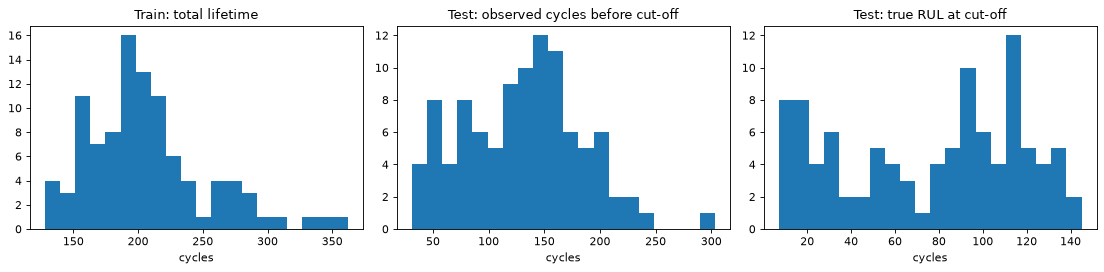

In [2]:
life = train.groupby("unit").cycle.max()
test_len = test.groupby("unit").cycle.max()
summary = pd.DataFrame(
    {
        "train lifetime (cycles)": life.describe(),
        "test observed cycles": test_len.describe(),
        "test true RUL": true_rul.rul.describe(),
    }
).round(1)
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(life, bins=20)
axes[0].set_title("Train: total lifetime")
axes[1].hist(test_len, bins=20)
axes[1].set_title("Test: observed cycles before cut-off")
axes[2].hist(true_rul.rul, bins=20)
axes[2].set_title("Test: true RUL at cut-off")
for ax in axes:
    ax.set_xlabel("cycles")
fig.tight_layout()
fig.savefig(FIG / "eda_lifetimes.png", dpi=90)

## 2. Constant and uninformative columns

In [3]:
stats = train.drop(columns=["unit", "cycle"]).agg(["std", "nunique"]).T
stats["name"] = stats.index.map(lambda c: SENSOR_NAMES.get(c, "operational setting"))
display(stats.sort_values("std").round(5))
constant = stats.index[stats["nunique"] <= 2].tolist()
print("Constant or near-constant (<= 2 distinct values):", constant)

,std,nunique,name
s1,0.00000,1.0,T2 fan inlet temp
op3,0.00000,1.0,operational setting
s10,0.00000,1.0,epr engine pressure ratio
s19,0.00000,1.0,PCNfR_dmd demanded corrected fan speed
s18,0.00000,1.0,Nf_dmd demanded fan speed
s16,0.00000,1.0,farB burner fuel-air ratio
s5,0.00000,1.0,P2 fan inlet pressure
op2,0.00029,13.0,operational setting
s6,0.00139,2.0,P15 bypass duct pressure
op1,0.00219,158.0,operational setting


Constant or near-constant (<= 2 distinct values): ['op3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']


## 3. Sensor trends over engine life

Each line is one engine, aligned so that x = 0 is the failure cycle. A rolling mean of 10 cycles is overlaid in black for the fleet median.

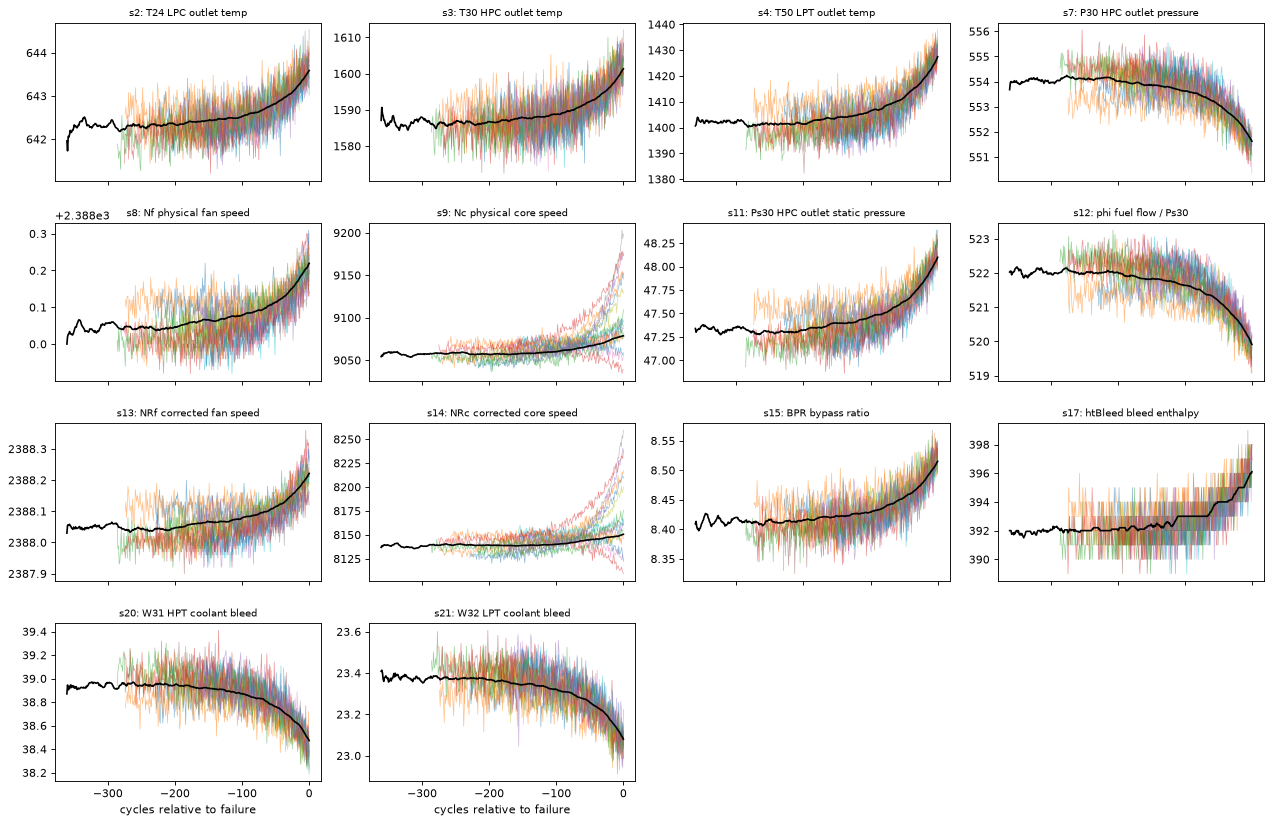

In [4]:
train["rul"] = train.groupby("unit").cycle.transform("max") - train.cycle
informative = [s for s in SENSOR_NAMES if s not in constant]
rng = np.random.default_rng(0)
sample_units = rng.choice(train.unit.unique(), size=15, replace=False)

n = len(informative)
fig, axes = plt.subplots(int(np.ceil(n / 4)), 4, figsize=(16, 2.6 * np.ceil(n / 4)), sharex=True)
for ax, s in zip(axes.flat, informative, strict=False):
    for u in sample_units:
        e = train[train.unit == u]
        ax.plot(-e.rul, e[s], lw=0.6, alpha=0.5)
    med = train.groupby("rul")[s].median().sort_index(ascending=False)
    ax.plot(-med.index, med.rolling(10, min_periods=1).mean(), color="black", lw=1.5)
    ax.set_title(f"{s}: {SENSOR_NAMES[s]}", fontsize=9)
for ax in axes.flat[n:]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("cycles relative to failure")
fig.tight_layout()
fig.savefig(FIG / "eda_sensor_trends.png", dpi=90)

## 4. Correlation with RUL

,spearman with RUL
s11,-0.718
s4,-0.702
s12,0.693
s7,0.679
s15,-0.666
s21,0.657
s20,0.653
s17,-0.629
s2,-0.629
s3,-0.606


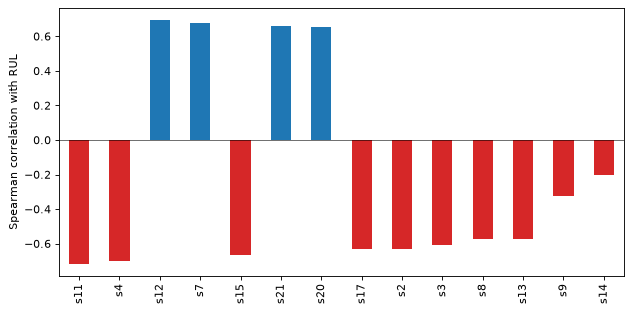

In [5]:
corr = train[informative + ["rul"]].corr(method="spearman")["rul"].drop("rul")
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
display(corr.round(3).to_frame("spearman with RUL"))

fig, ax = plt.subplots(figsize=(8, 4))
corr.plot.bar(ax=ax, color=["tab:red" if v < 0 else "tab:blue" for v in corr])
ax.set_ylabel("Spearman correlation with RUL")
ax.axhline(0, color="black", lw=0.5)
fig.tight_layout()
fig.savefig(FIG / "eda_rul_correlation.png", dpi=90)

In [6]:
# Early-life vs late-life: correlation is weak far from failure (the 'flat' phase).
early = train[train.rul > 125][informative + ["rul"]].corr(method="spearman")["rul"].drop("rul")
late = train[train.rul <= 125][informative + ["rul"]].corr(method="spearman")["rul"].drop("rul")
display(pd.DataFrame({"RUL > 125": early, "RUL <= 125": late}).reindex(corr.index).round(3))

,RUL > 125,RUL <= 125
s11,-0.181,-0.758
s4,-0.161,-0.737
s12,0.165,0.733
s7,0.149,0.716
s15,-0.144,-0.709
s21,0.148,0.691
s20,0.129,0.687
s17,-0.112,-0.664
s2,-0.136,-0.670
s3,-0.124,-0.642


## 5. Inter-sensor redundancy

Highly correlated sensor pairs carry overlapping information. Tree models cope with this, but it matters for linear baselines and for interpreting feature importance.

In [7]:
c = train[informative].corr().abs()
pairs = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
display(pairs[pairs > 0.8].round(3).to_frame("|pearson|"))

,,|pearson|
s9,s14,0.963
s11,s12,0.847
s4,s11,0.830
s8,s13,0.826
s7,s11,0.823
s4,s12,0.816
s7,s12,0.813


## Key findings (FD001)

1. **Size and lifetimes.** 100 training engines (20,631 rows), lifetimes 128 to 362 cycles (median 199). 100 test engines are cut off after 31 to 303 cycles; their true RUL ranges from 7 to 145 (median 86).
2. **Drop 7 sensors plus op3.** s1, s5, s10, s16, s18, s19 and op3 are exactly constant; s6 takes only 2 values. They carry no information in FD001. (In FD002/FD004 some of these vary with operating condition, so the drop list must be computed per subset, not hard-coded.)
3. **op1 and op2 are noise here.** FD001 has a single operating condition, so the tiny variation in op1/op2 is not a useful signal.
4. **14 informative sensors, two trend groups.** s2, s3, s4, s8, s11, s13, s15, s17 rise towards failure; s7, s12, s20, s21 fall. s9 and s14 (core speeds) diverge: they go up for some engines and down for others, so their overall correlation with RUL is weak (-0.32, -0.20).
5. **Degradation is flat, then accelerates.** Sensors look stable for most of the life and change visibly only in roughly the last 100 to 150 cycles. Correlation with RUL is about 0.15 when RUL > 125 and about 0.7 when RUL <= 125. This is the empirical reason for the piecewise-linear RUL cap in Milestone 2: far from failure, the data cannot tell 200 from 150 remaining cycles.
6. **Single readings are noisy.** Cycle-to-cycle noise is large compared with the trend, which motivates rolling-window features (Milestone 3).
7. **Redundancy.** s9 and s14 are almost duplicates (|r| = 0.96), and the HPC group s4, s7, s11, s12 is strongly inter-correlated (0.81 to 0.85). Fine for trees, relevant for linear baselines and for reading feature importance.
